In [1]:
import matplotlib 
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

import pandas as pd
import re

from mpl_toolkits.axes_grid1 import ImageGrid

mm = 1/25.4
srt_factor = 100

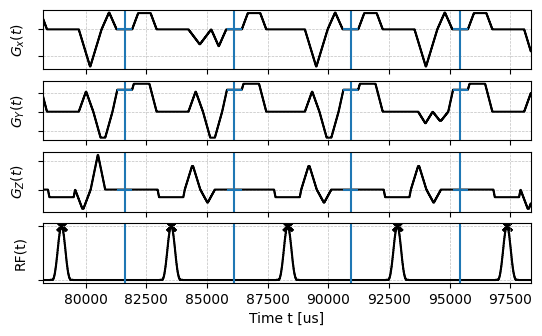

In [7]:
# 200rpm, fast
prot = r'Z:\_allgemein\projects\Hannes\rot_phantom_12082024\protocols_for_eval\003 - CCW_7_cor_venc150_200rpm_135cms_10avgs_fast\SimulationProtocol.txt'
te_shift = 0

df = pd.read_csv(prot, header=5, sep='\t', dtype=np.float64, skip_blank_lines=True, skipinitialspace=True)

df.rename(columns=lambda c: re.sub('[^a-zA-Z0-9 , . ( ) -]', '', c), inplace=True)

df.rename(columns=lambda x: x.strip(), inplace=True)

plt.rcParams.update({'font.size': 10})
fig0, ax = plt.subplots(nrows=4, ncols=1, figsize=(160*mm, 90*mm), sharex=True) # figsize: pixel size for latex

plot1 = ax[0].plot(np.arange(df['X Gradient'].shape[0]), df['X Gradient'], color='black')
plot2 = ax[2].plot(df['Y Gradient'], color='black')
plot3 = ax[1].plot(df['Z Gradient'], color='black')
plot4 = ax[3].plot(df['RF-Signal (ch. 1, 1H, 123.2 MHz)'], color='black')

adc_events = np.diff(df['ADC Signal Data'])
adc_events_time = np.arange(adc_events.shape[0]) + 0.5

adc_events_begin = np.argwhere(adc_events == 1).reshape([-1])
adc_events_end = np.argwhere(adc_events == -1).reshape([-1])

# if the simulation cut off an ADC starting or ending event, we only consider ADCs which start and end in the simulation timespan
min_events = np.minimum(adc_events_begin.shape[0], adc_events_end.shape[0])
adc_events_begin = adc_events_begin[:min_events]
adc_events_end = adc_events_end[:min_events]


# assuming no asymmetric echo
adc_echoes_idx = (adc_events_end - adc_events_begin) / 2 + adc_events_begin

for adc_event_begin, adc_event_end, adc_echo_idx in zip(adc_events_begin, adc_events_end, adc_echoes_idx):
    ax[0].hlines(df['X Gradient'][np.floor(adc_echo_idx)], adc_event_begin, adc_event_end)
    ax[2].hlines(df['Y Gradient'][np.floor(adc_echo_idx)], adc_event_begin, adc_event_end)
    ax[1].hlines(df['Z Gradient'][np.floor(adc_echo_idx)], adc_event_begin, adc_event_end)
    # for axis in ax:
        # axis.axvspan(adc_event_begin, adc_event_end, facecolor='orange')

for adc_echo_idx in adc_echoes_idx:
    for axis in ax:
        axis.axvline(adc_echo_idx)
        
rf_max = df['RF-Signal (ch. 1, 1H, 123.2 MHz)'].max()
time_vec = np.arange(df['RF-Signal (ch. 1, 1H, 123.2 MHz)'].shape[0])
rf_centers = np.argwhere(df['RF-Signal (ch. 1, 1H, 123.2 MHz)'] == rf_max).reshape([-1])
ax[3].scatter(rf_centers, df['RF-Signal (ch. 1, 1H, 123.2 MHz)'][rf_centers], marker='x', color='black')


# ax[0].set_ylabel('Phase encoding\ngradient [mT/m]')
# ax[1].set_ylabel('Slice encoding\ngradient [mT/m]')
# ax[2].set_ylabel('Frequency encoding\ngradient [mT/m]')
# ax[3].set_ylabel('RF [a.u.]')

####
for i in range(4):
    ax[i].grid(color='silver', linestyle='--', linewidth=0.5)
    # ax[i].spines['bottom'].set_color('k')
    # ax[i].spines['left'].set_color('k')
    # ax[i].spines['right'].set_color('k')
    # ax[i].spines['top'].set_color('k')
    ax[i].set_yticklabels(())

# plt.savefig("full_gradients" + save_format)

# ax[0].set_xlim(left=adc_echoes_idx[-2], right=adc_echoes_idx[-1])
ax[0].set_xlim(left=rf_centers[-101]*0.99, right=rf_centers[-1]*1.01)

ax[0].set_ylabel('$G_x(t)$')
ax[1].set_ylabel('$G_Y(t)$')
ax[2].set_ylabel('$G_Z(t)$')
ax[3].set_ylabel('RF(t)')
ax[3].set_xlabel('Time t [us]')

# ax[0].set_xticks(())


plt.savefig("gradients_BEAT.svg")

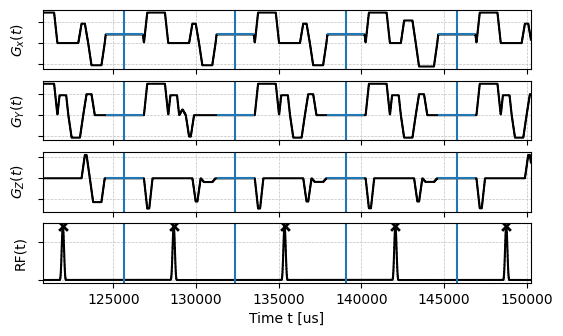

In [8]:
prot = r'C:\Users\dillin01\Documents\rotphantomPUB\rotationalphantom\cmrseq_venc100_bernstein_BW892\SimulationProtocol.txt'


df = pd.read_csv(prot, header=5, sep='\t', dtype=np.float64, skip_blank_lines=True, skipinitialspace=True)

df.rename(columns=lambda c: re.sub('[^a-zA-Z0-9 , . ( ) -]', '', c), inplace=True)

df.rename(columns=lambda x: x.strip(), inplace=True)

plt.rcParams.update({'font.size': 10})
fig0, ax = plt.subplots(nrows=4, ncols=1, figsize=(160*mm, 90*mm), sharex=True) # figsize: pixel size for latex

plot1 = ax[0].plot(df['X Gradient (GPA 0)'], color='black')
plot2 = ax[2].plot(df['Y Gradient (GPA 0)'], color='black')
plot3 = ax[1].plot(df['Z Gradient (GPA 0)'], color='black')
plot4 = ax[3].plot(df['RF-Signal (ch. 1, 1H, 123.2 MHz)'], color='black')

adc_events = np.diff(df['ADC Signal Data'])
adc_events_time = np.arange(adc_events.shape[0]) + 0.5

adc_events_begin = np.argwhere(adc_events == 1).reshape([-1])
adc_events_end = np.argwhere(adc_events == -1).reshape([-1])

# if the simulation cut off an ADC starting or ending event, we only consider ADCs which start and end in the simulation timespan
min_events = np.minimum(adc_events_begin.shape[0], adc_events_end.shape[0])
adc_events_begin = adc_events_begin[:min_events]
adc_events_end = adc_events_end[:min_events]


# assuming no asymmetric echo
adc_echoes_idx = (adc_events_end - adc_events_begin) / 2 + adc_events_begin

for adc_event_begin, adc_event_end, adc_echo_idx in zip(adc_events_begin, adc_events_end, adc_echoes_idx):
    ax[0].hlines(df['X Gradient (GPA 0)'][np.floor(adc_echo_idx)], adc_event_begin, adc_event_end)
    ax[2].hlines(df['Y Gradient (GPA 0)'][np.floor(adc_echo_idx)], adc_event_begin, adc_event_end)
    ax[1].hlines(df['Z Gradient (GPA 0)'][np.floor(adc_echo_idx)], adc_event_begin, adc_event_end)
    # for axis in ax:
        # axis.axvspan(adc_event_begin, adc_event_end, facecolor='orange')

for adc_echo_idx in adc_echoes_idx:
    for axis in ax:
        axis.axvline(adc_echo_idx)
        
rf_max = df['RF-Signal (ch. 1, 1H, 123.2 MHz)'].max()
time_vec = np.arange(df['RF-Signal (ch. 1, 1H, 123.2 MHz)'].shape[0])
rf_centers = np.argwhere(df['RF-Signal (ch. 1, 1H, 123.2 MHz)'] == rf_max).reshape([-1])
ax[3].scatter(rf_centers, df['RF-Signal (ch. 1, 1H, 123.2 MHz)'][rf_centers], marker='x', color='black')


# ax[0].set_ylabel('Phase encoding\ngradient [mT/m]')
# ax[1].set_ylabel('Slice encoding\ngradient [mT/m]')
# ax[2].set_ylabel('Frequency encoding\ngradient [mT/m]')
# ax[3].set_ylabel('RF [a.u.]')

####
for i in range(4):
    ax[i].grid(color='silver', linestyle='--', linewidth=0.5)
    # ax[i].spines['bottom'].set_color('k')
    # ax[i].spines['left'].set_color('k')
    # ax[i].spines['right'].set_color('k')
    # ax[i].spines['top'].set_color('k')
    ax[i].set_yticklabels(())

# plt.savefig("full_gradients" + save_format)

ax[0].set_ylabel('$G_x(t)$')
ax[1].set_ylabel('$G_Y(t)$')
ax[2].set_ylabel('$G_Z(t)$')
ax[3].set_ylabel('RF(t)')
ax[3].set_xlabel('Time t [us]')

# ax[0].set_xlim(left=adc_echoes_idx[-2], right=adc_echoes_idx[-1])
ax[0].set_xlim(left=rf_centers[91]*0.99, right=rf_centers[-1]*1.01)

# ax[0].set_xticks(())


plt.savefig("gradients_CMR_illustrative.svg")

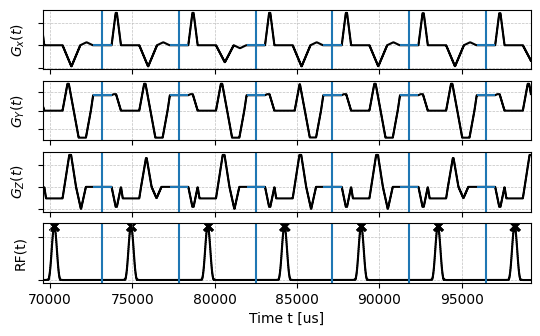

In [2]:
# 500rpm, fast
# prot = r'Z:\_allgemein\projects\Hannes\rot_phantom_12082024\protocols_for_eval\009 - CCW_13_cor_venc400_500rpm_135cms_10avgs_fast\SimulationProtocol.txt'
prot = r'Z:\_allgemein\projects\Hannes\rotphantom_PUB_v2\poet\BEAT_FQ_venc500_BW893_dyn16_rpm50_dir1.txt'

te_shift = 0

df = pd.read_csv(prot, header=5, sep='\t', dtype=np.float64, skip_blank_lines=True, skipinitialspace=True)

df.rename(columns=lambda c: re.sub('[^a-zA-Z0-9 , . ( ) -]', '', c), inplace=True)

df.rename(columns=lambda x: x.strip(), inplace=True)

plt.rcParams.update({'font.size': 10})
fig0, ax = plt.subplots(nrows=4, ncols=1, figsize=(160*mm, 90*mm), sharex=True) # figsize: pixel size for latex

plot1 = ax[0].plot(np.arange(df['X Gradient'].shape[0]), df['X Gradient'], color='black')
plot2 = ax[2].plot(df['Y Gradient'], color='black')
plot3 = ax[1].plot(df['Z Gradient'], color='black')
plot4 = ax[3].plot(df['RF-Signal (ch. 1, 1H, 123.2 MHz)'], color='black')

adc_events = np.diff(df['ADC Signal Data'])
adc_events_time = np.arange(adc_events.shape[0]) + 0.5

adc_events_begin = np.argwhere(adc_events == 1).reshape([-1])
adc_events_end = np.argwhere(adc_events == -1).reshape([-1])

# if the simulation cut off an ADC starting or ending event, we only consider ADCs which start and end in the simulation timespan
min_events = np.minimum(adc_events_begin.shape[0], adc_events_end.shape[0])
adc_events_begin = adc_events_begin[:min_events]
adc_events_end = adc_events_end[:min_events]


# assuming no asymmetric echo
adc_echoes_idx = (adc_events_end - adc_events_begin) / 2 + adc_events_begin

for adc_event_begin, adc_event_end, adc_echo_idx in zip(adc_events_begin, adc_events_end, adc_echoes_idx):
    ax[0].hlines(df['X Gradient'][np.floor(adc_echo_idx)], adc_event_begin, adc_event_end)
    ax[2].hlines(df['Y Gradient'][np.floor(adc_echo_idx)], adc_event_begin, adc_event_end)
    ax[1].hlines(df['Z Gradient'][np.floor(adc_echo_idx)], adc_event_begin, adc_event_end)
    # for axis in ax:
        # axis.axvspan(adc_event_begin, adc_event_end, facecolor='orange')

for adc_echo_idx in adc_echoes_idx:
    for axis in ax:
        axis.axvline(adc_echo_idx)
        
rf_max = df['RF-Signal (ch. 1, 1H, 123.2 MHz)'].max()
time_vec = np.arange(df['RF-Signal (ch. 1, 1H, 123.2 MHz)'].shape[0])
rf_centers = np.argwhere(df['RF-Signal (ch. 1, 1H, 123.2 MHz)'] == rf_max).reshape([-1])
ax[3].scatter(rf_centers, df['RF-Signal (ch. 1, 1H, 123.2 MHz)'][rf_centers], marker='x', color='black')


# ax[0].set_ylabel('Phase encoding\ngradient [mT/m]')
# ax[1].set_ylabel('Slice encoding\ngradient [mT/m]')
# ax[2].set_ylabel('Frequency encoding\ngradient [mT/m]')
# ax[3].set_ylabel('RF [a.u.]')

####
for i in range(4):
    ax[i].grid(color='silver', linestyle='--', linewidth=0.5)
    # ax[i].spines['bottom'].set_color('k')
    # ax[i].spines['left'].set_color('k')
    # ax[i].spines['right'].set_color('k')
    # ax[i].spines['top'].set_color('k')
    ax[i].set_yticklabels(())

# plt.savefig("full_gradients" + save_format)

# ax[0].set_xlim(left=adc_echoes_idx[-2], right=adc_echoes_idx[-1])
ax[0].set_xlim(left=rf_centers[-101]*0.99, right=rf_centers[-1]*1.01)

ax[0].set_ylabel('$G_x(t)$')
ax[1].set_ylabel('$G_Y(t)$')
ax[2].set_ylabel('$G_Z(t)$')
ax[3].set_ylabel('RF(t)')
ax[3].set_xlabel('Time t [us]')

# ax[0].set_xticks(())


plt.savefig("gradients_BEAT.svg")

Auto tolerance: 2
Merged centers: [51612 56272 60932 65592 70252 74912 79572 84232 88892 93552 98212]
Extracted 10 repetitions


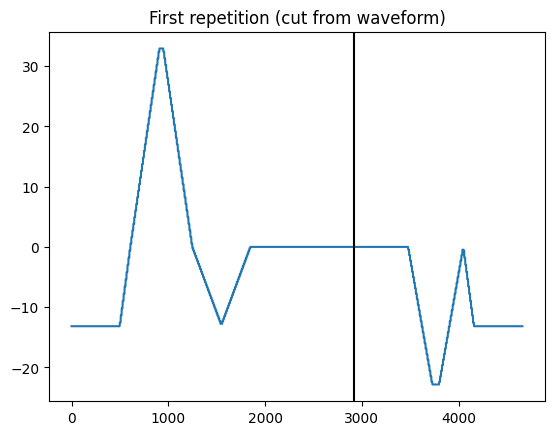

In [3]:
def merge_close_centers_auto(rf_centers, method="mean"):
    """
    Automatically merge close rf_centers based on spacing distribution.
    """
    rf_centers = np.sort(np.unique(rf_centers))
    diffs = np.diff(rf_centers)

    # Pick tolerance: twice the smallest observed gap
    tolerance = int(np.min(diffs) * 2) if len(diffs) > 0 else 1

    merged = []
    cluster = [rf_centers[0]]

    for val in rf_centers[1:]:
        if val - cluster[-1] <= tolerance:
            cluster.append(val)
        else:
            if method == "mean":
                merged.append(int(np.round(np.mean(cluster))))
            elif method == "median":
                merged.append(int(np.median(cluster)))
            elif method == "first":
                merged.append(cluster[0])
            cluster = [val]

    # finalize last cluster
    if cluster:
        if method == "mean":
            merged.append(int(np.round(np.mean(cluster))))
        elif method == "median":
            merged.append(int(np.median(cluster)))
        elif method == "first":
            merged.append(cluster[0])

    return np.array(merged), tolerance


def split_waveform_by_centers(waveform, rf_centers):
    """
    Split waveform into segments from one rf_center to the next.
    
    Parameters:
        waveform (1D array): full waveform
        rf_centers (array): detected rf centers (will be merged automatically)
    
    Returns:
        list of np.ndarray: segments (one per repetition)
        np.ndarray: merged centers
        int: tolerance used
    """
    merged_centers, tol = merge_close_centers_auto(rf_centers)
    segments = []

    for i in range(len(merged_centers) - 1):
        start = merged_centers[i]
        end = merged_centers[i+1]
        segments.append(waveform[start:end])

    return segments, merged_centers, tol


segments, merged_centers, tol = split_waveform_by_centers(df['Y Gradient'], rf_centers)

print("Auto tolerance:", tol)
print("Merged centers:", merged_centers)
print(f"Extracted {len(segments)} repetitions")

plt.plot(segments[-1].to_numpy())
plt.axvline(2920, color='k')
# for segment in segments:
#     plt.plot(segment)
plt.title("First repetition (cut from waveform)")
plt.show()


Auto tolerance: 2
Merged centers: [51605 56265 60925 65585 70245 74905 79565 84225 88885 93545 98205]
Extracted 10 repetitions


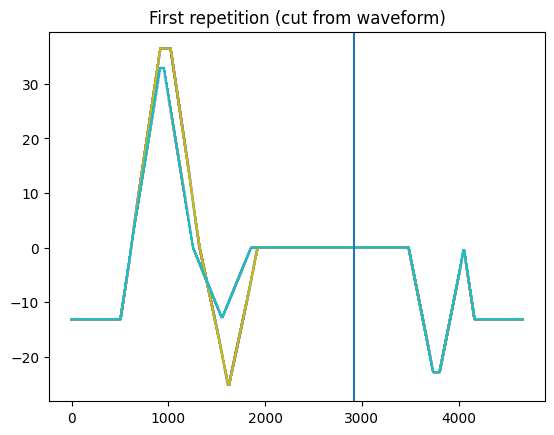

In [4]:

def merge_close_centers_auto(rf_centers, method="first"):
    """
    Automatically merge close rf_centers based on spacing distribution.
    """
    rf_centers = np.sort(np.unique(rf_centers))
    diffs = np.diff(rf_centers)

    # Pick tolerance: twice the smallest observed gap
    tolerance = int(np.min(diffs) * 2) if len(diffs) > 0 else 1

    merged = []
    cluster = [rf_centers[0]]

    for val in rf_centers[1:]:
        if val - cluster[-1] <= tolerance:
            cluster.append(val)
        else:
            if method == "mean":
                merged.append(int(np.round(np.mean(cluster))))
            elif method == "median":
                merged.append(int(np.median(cluster)))
            elif method == "first":
                merged.append(cluster[0])
            cluster = [val]

    # finalize last cluster
    if cluster:
        if method == "mean":
            merged.append(int(np.round(np.mean(cluster))))
        elif method == "median":
            merged.append(int(np.median(cluster)))
        elif method == "first":
            merged.append(cluster[0])

    return np.array(merged), tolerance


def split_waveform_fixed_length(waveform, rf_centers):
    """
    Split waveform into equal-length repetitions from one center to the next.
    
    Parameters:
        waveform (1D array): full waveform
        rf_centers (array): detected rf centers (will be merged automatically)
    
    Returns:
        np.ndarray: shape (n_reps, segment_length), repetitions
        np.ndarray: merged centers
        int: tolerance used
    """
    merged_centers, tol = merge_close_centers_auto(rf_centers)

    # segment length = min distance between centers
    diffs = np.diff(merged_centers)
    seg_len = np.min(diffs)

    segments = []
    for i in range(len(merged_centers) - 1):
        start = merged_centers[i]
        end = start + seg_len
        if end <= len(waveform):
            segments.append(waveform[start:end])

    return np.array(segments), merged_centers, tol



merged_centers, tol = merge_close_centers_auto(rf_centers)

print("Auto tolerance:", tol)
print("Merged centers:", merged_centers)
print(f"Extracted {len(segments)} repetitions")


plt.figure()
for i in range(0, len(merged_centers)-1):
    # plt.plot(df['X Gradient'][merged_centers[i]:merged_centers[i+1]])
    # plt.plot(df['Y Gradient'][merged_centers[i]:merged_centers[i+1]])
    plt.plot(df['Y Gradient'][merged_centers[i]:merged_centers[i+1]].to_numpy())
    # plt.plot(df['Z Gradient'][merged_centers[i]:merged_centers[i+1]])
    
plt.axvline(2920)
# for adc_echo_idx in adc_echoes_idx:
#     plt.axvline(adc_echo_idx)
# for i in range(0, len(merged_centers)-1):
#     plt.plot(df['X Gradient'][merged_centers[i]:merged_centers[i+1]].to_numpy())
#     plt.plot(df['Y Gradient'][merged_centers[i]:merged_centers[i+1]].to_numpy())
#     plt.plot(df['Z Gradient'][merged_centers[i]:merged_centers[i+1]].to_numpy())

# plt.axes().set_xlim(left=rf_centers[-101]*0.99, right=rf_centers[-1]*1.01)
# plt.xlim((80000, 90000))
plt.title("First repetition (cut from waveform)")
plt.show()



t_ref = 979 us
tgx: 1504.3333676850098 us
tgy: 893.3201028863966 us
tgz: 979.9248528100902 us
Difference in x axis second moment at TE: 2.4007904891456134e-12 m/s3
aencx at TE: 9782.85913622155 m/s2
Difference in x axis first moment at TE: 2.348764357236607e-09 m/s2
vencx at TE: 4.9997768185065325 m/s
Difference in y axis second moment at TE: -1.844914896505476e-12 m/s3
aency at TE: -12730.449093006313 m/s2
Difference in y axis first moment at TE: -2.348764053589289e-09 m/s2
vency at TE: -4.999777464875766 m/s
Difference in z axis second moment at TE: -1.4239496318750806e-13 m/s3
aencz at TE: -164939.78891630057 m/s2
Difference in z axis first moment at TE: -2.348766526791051e-09 m/s2
vencz at TE -4.999772200215234 m/s


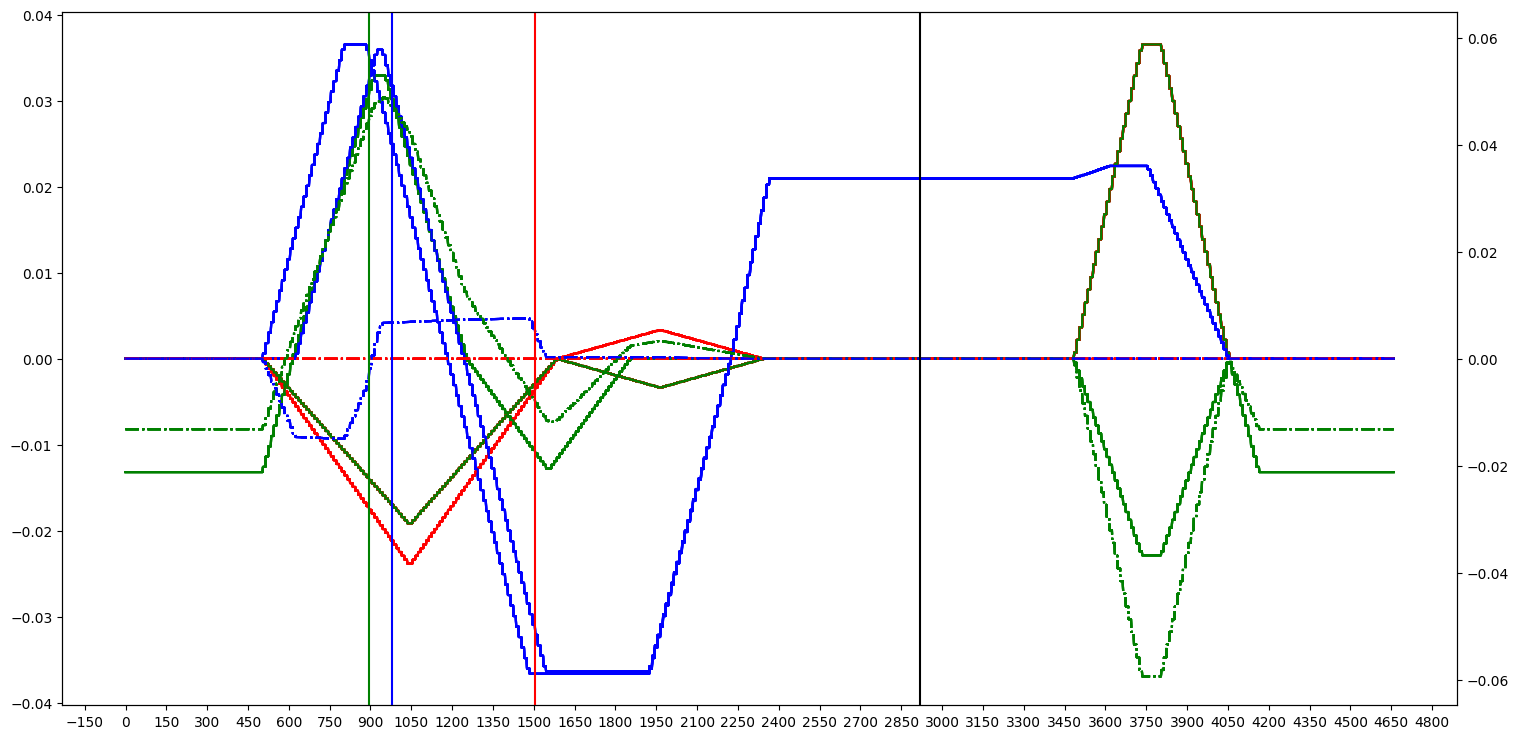

<Figure size 640x480 with 0 Axes>

In [137]:
from scipy.integrate import cumulative_simpson
from matplotlib.ticker import MaxNLocator

def gradient_moment(grad_waveform, dt, order=2, t0=0.0):
    """
    Compute the n-th order gradient moment for an MRI gradient waveform.
    
    Parameters:
        grad_waveform (1D array): gradient values over time [T/m]
        dt (float): sampling interval [s]
        order (int): order of the moment (default=2 for second order)
    
    Returns:
        float: n-th order gradient moment
    """
    order = int(order)
    t = np.arange(len(grad_waveform)) * dt - t0
    moment = cumulative_simpson(y=grad_waveform * (t**order), x=t)
    # print(np.any(np.isnan(moment)))
    return moment

dt = 1e-6
# te = 2510
te = 2920

# t_ref = 0.0
# t_ref = te*1e-6
# t_ref = tgx * 1e-6
# t_ref = tgy * 1e-6
t_ref = tgz * 1e-6


# x acc compensated
# t_ref = 0.00156

# y acc compensated
# t_ref = 0.0012

# # z acc compensated
# t_ref = 0.00125

# t = df['X Gradient']

# nonencoded segment
idx = 0
data_frame = df['X Gradient'][merged_centers[idx]:merged_centers[idx+1]]*1e-3 # mT/m
gx_nonenc = data_frame
m2x_nonenc = gradient_moment(data_frame.to_numpy(), dt, t0=t_ref)
m1x_nonenc = gradient_moment(data_frame.to_numpy(), dt, order=1, t0=t_ref)
m0x_nonenc = gradient_moment(data_frame.to_numpy(), dt, order=0, t0=t_ref)
# encoded segment
idx = 2
data_frame = df['X Gradient'][merged_centers[idx]:merged_centers[idx+1]]*1e-3 # mT/m
gx_enc = data_frame
m2x_enc = gradient_moment(data_frame.to_numpy(), dt, t0=t_ref)
m1x_enc = gradient_moment(data_frame.to_numpy(), dt, order=1, t0=t_ref)
m0x_enc = gradient_moment(data_frame.to_numpy(), dt, order=0, t0=t_ref)

# nonencoded segment
idx = 0
gy_nonenc = data_frame
data_frame = df['Y Gradient'][merged_centers[idx]:merged_centers[idx+1]]*1e-3 # mT/m
m2y_nonenc = gradient_moment(data_frame.to_numpy(), dt, t0=t_ref)
m1y_nonenc = gradient_moment(data_frame.to_numpy(), dt, order=1, t0=t_ref)
m0y_nonenc = gradient_moment(data_frame.to_numpy(), dt, order=0, t0=t_ref)
# encoded segment
idx = 1
data_frame = df['Y Gradient'][merged_centers[idx]:merged_centers[idx+1]]*1e-3 # mT/m
gy_enc = data_frame
m2y_enc = gradient_moment(data_frame.to_numpy(), dt, t0=t_ref)
m1y_enc = gradient_moment(data_frame.to_numpy(), dt, order=1, t0=t_ref)
m0y_enc = gradient_moment(data_frame.to_numpy(), dt, order=0, t0=t_ref)

# nonencoded segment
idx = 0
data_frame = df['Z Gradient'][merged_centers[idx]:merged_centers[idx+1]]*1e-3 # mT/m
gz_nonenc = data_frame
m2z_nonenc = gradient_moment(data_frame.to_numpy(), dt, t0=t_ref)
m1z_nonenc = gradient_moment(data_frame.to_numpy(), dt, order=1, t0=t_ref)
m0z_nonenc = gradient_moment(data_frame.to_numpy(), dt, order=0, t0=t_ref)
# encoded segment
idx = 3
data_frame = df['Z Gradient'][merged_centers[idx]:merged_centers[idx+1]]*1e-3 # mT/m
gz_enc = data_frame
m2z_enc = gradient_moment(data_frame.to_numpy(), dt, t0=t_ref)
m1z_enc = gradient_moment(data_frame.to_numpy(), dt, order=1, t0=t_ref)
m0z_enc = gradient_moment(data_frame.to_numpy(), dt, order=0, t0=t_ref)

gx_diff = np.abs(gx_enc.to_numpy()[0:len(m1x_nonenc)] - gx_nonenc.to_numpy()[0:len(m1x_nonenc)])
# tgx = np.abs(gradient_moment(gx_diff, dt, order=1, t0=0)[te] / gradient_moment(gx_diff, dt, order=0, t0=0)[te]) * 1e6
tgx = gradient_moment(np.abs(gx_diff), dt, order=1, t0=0)[te] / gradient_moment(np.abs(gx_diff), dt, order=0, t0=0)[te] * 1e6
# print(tgx)

gy_diff = np.abs(gy_enc.to_numpy()[0:len(m1x_nonenc)] - gy_nonenc.to_numpy()[0:len(m1x_nonenc)])
# tgy = np.abs(gradient_moment(gy_diff, dt, order=1, t0=0)[te] / gradient_moment(gy_diff, dt, order=0, t0=0)[te]) * 1e6
tgy = gradient_moment(np.abs(gy_diff), dt, order=1, t0=0)[te] / gradient_moment(np.abs(gy_diff), dt, order=0, t0=0)[te] * 1e6
# print(tgy)

gz_diff = np.abs(gz_enc.to_numpy()[0:len(m1x_nonenc)] - gz_nonenc.to_numpy()[0:len(m1x_nonenc)])
# tgz = np.abs(gradient_moment(gz_diff, dt, order=1, t0=0)[te] / gradient_moment(gz_diff, dt, order=0, t0=0)[te]) * 1e6
tgz = gradient_moment(np.abs(gz_diff), dt, order=1, t0=0)[te] / gradient_moment(np.abs(gz_diff), dt, order=0, t0=0)[te] * 1e6
# print(tgz)

# plt.figure()
fig, ax1 = plt.subplots(figsize=(18, 9))
ax2 = ax1.twinx()  # instantiate a second Axes that shares the same x-axis

for i in range(0, len(merged_centers)-1):
    # plt.plot(m2x_enc)
    # plt.plot(m2x_nonenc)
    
    # ax1.plot(m2x_enc[0:len(m2x_nonenc)] - m2x_nonenc[0:len(m2x_nonenc)], 'r')
    # ax1.plot(m2y_enc - m2y_nonenc, 'g')
    # ax1.plot(m2z_enc - m2z_nonenc, 'b')
    
    # ax2.plot(m1x_enc[0:len(m1y_nonenc)] - m1x_nonenc[0:len(m1y_nonenc)], color='r', linestyle='-.')
    # ax2.plot(m1y_enc - m1y_nonenc, color='g', linestyle='-.')
    # ax2.plot(m1z_enc - m1z_nonenc, color='b', linestyle='-.')
    
    gx_diff = gradient_moment(gx_enc.to_numpy()[0:len(gx_nonenc)] - gx_nonenc.to_numpy()[0:len(gx_nonenc)], dt=dt, order=0, t0=t_ref)
    # gx_diff = m0x_enc[0:len(m0x_nonenc)] - m0x_nonenc[0:len(m0x_nonenc)]
    nz_start = np.argmax(gx_diff != 0)
    sign_changes = np.where(np.sign(gx_diff[nz_start:-1]) != np.sign(gx_diff[nz_start+1:]))[0]
    gx_zc = nz_start + sign_changes[0]
    # print(gx_zc)
    
    gy_diff = gy_enc.to_numpy()[0:len(gy_enc)] - gy_nonenc.to_numpy()[0:len(gy_enc)]
    # gy_diff = m0y_enc - m0y_nonenc
    nz_start = np.argmax(gy_diff != 0)
    sign_changes = np.where(np.sign(gy_diff[nz_start:-1]) != np.sign(gy_diff[nz_start+1:]))[0]
    gy_zc = nz_start + sign_changes[0]
    # print(gy_zc)
    
    gz_diff = gz_enc.to_numpy()[0:len(gz_enc)] - gz_nonenc.to_numpy()[0:len(gz_nonenc)]
    # gz_diff = m0z_enc - m0z_nonenc
    nz_start = np.argmax(gz_diff != 0)
    sign_changes = np.where(np.sign(gz_diff[nz_start:-1]) != np.sign(gz_diff[nz_start+1:]))[0]
    gz_zc = nz_start + sign_changes[0]
    # print(gz_zc)
    
    ax2.plot(gx_diff, color='r', linestyle='-.')
    ax1.plot(gx_enc.to_numpy(), color='r', linestyle='-')
    ax1.plot(gx_nonenc.to_numpy(), color='r', linestyle='-')
    ax2.plot(gy_diff, color='g', linestyle='-.')
    ax1.plot(gy_enc.to_numpy(), color='g', linestyle='-')
    ax1.plot(gy_nonenc.to_numpy(), color='g', linestyle='-')
    ax2.plot(gz_diff, color='b', linestyle='-.')
    ax1.plot(gz_enc.to_numpy(), color='b', linestyle='-')
    ax1.plot(gz_nonenc.to_numpy(), color='b', linestyle='-')
    
    # ax2.plot(m1x_enc[0:len(m1x_enc)], color='k', linestyle='-.')
    # ax2.plot(m1x_nonenc[0:len(m1x_nonenc)], color='r', linestyle='-.')
    
    # ax2.plot(m1y_enc[0:len(m1y_enc)], color='k', linestyle='-.')
    # ax2.plot(m1y_nonenc[0:len(m1y_nonenc)], color='r', linestyle='-.')
    
    # ax2.plot(m1z_enc[0:len(m1z_enc)], color='k', linestyle='-.')
    # ax2.plot(m1z_nonenc[0:len(m1z_nonenc)], color='r', linestyle='-.')
    
    
    # ax2.plot(m0x_enc[0:len(m0y_nonenc)] - m0x_nonenc[0:len(m0y_nonenc)], color='r', linestyle='-.')
    # ax2.plot(m0y_enc - m0y_nonenc, color='g', linestyle='-.')
    # ax2.plot(m0z_enc - m0z_nonenc, color='b', linestyle='-.')
    
    # ax2.plot(m0x_enc, color='r', linestyle='-.')
    # ax2.plot(m0y_enc, color='g', linestyle='-.')
    # ax2.plot(m0z_enc, color='b', linestyle='-.')
    
    # plt.plot(m2y_enc)
    # plt.plot(m2y_nonenc)
    # plt.plot(m2z_enc)
    # plt.plot(m2z_nonenc)
    # plt.plot(m1x_enc)
    # plt.plot(m1x_nonenc)
    # plt.plot(m1y_enc)
    # plt.plot(m1y_nonenc)
    # plt.plot(m1z_enc)
    # plt.plot(m1z_nonenc)
    
# moment difference
# ax1.set_ylim((-0.25e-10, 0.25e-10))
# plt.ylim((-0.5e-10, 0.5e-10))

# dummy shots have no ADC events :/
# plt.axvline(adc_echoes_idx[0])
plt.axvline(te, color='k')
plt.axvline(tgx, color='r')
plt.axvline(tgy, color='g')
plt.axvline(tgz, color='b')
# plt.axvline(gx_zc, color='r')
# plt.axvline(gy_zc, color='g')
# plt.axvline(gz_zc, color='b')
# plt.axhline(0)

import mpl_axes_aligner
ax2.xaxis.set_major_locator(MaxNLocator(nbins=40))
mpl_axes_aligner.align.yaxes(ax1, 0, ax2, 0, 0.5)
# ax2.grid(which='x')

gamma = 2.6752218708e8

# t_ref_m2 = int(t_ref*1e6)
t_ref_m2 = int(te)

deltam2x = m2x_nonenc[t_ref_m2]-m2x_enc[t_ref_m2]
aencx = np.pi / (1/2 * gamma * deltam2x)
deltam1x = m1x_nonenc[t_ref_m2]-m1x_enc[t_ref_m2]
vencx = np.pi / (gamma * deltam1x)

deltam2y = m2y_nonenc[t_ref_m2]-m2y_enc[t_ref_m2]
aency = np.pi / (1/2 * gamma * deltam2y)
deltam1y = m1y_nonenc[t_ref_m2]-m1y_enc[t_ref_m2]
vency = np.pi / (gamma * deltam1y)

deltam2z = m2z_nonenc[t_ref_m2]-m2z_enc[t_ref_m2]
aencz = np.pi / (1/2 * gamma * deltam2z)
deltam1z = m1z_nonenc[t_ref_m2]-m1z_enc[t_ref_m2]
vencz = np.pi / (gamma * deltam1z)

print(f't_ref = {int(t_ref*1e6)} us')

print(f'tgx: {tgx} us')
print(f'tgy: {tgy} us')
print(f'tgz: {tgz} us')

print(f'Difference in x axis second moment at TE: {deltam2x} m/s3')
print(f'aencx at TE: {aencx} m/s2')
print(f'Difference in x axis first moment at TE: {deltam1x} m/s2')
print(f'vencx at TE: {vencx} m/s')

print(f'Difference in y axis second moment at TE: {deltam2y} m/s3')
print(f'aency at TE: {aency} m/s2')
print(f'Difference in y axis first moment at TE: {deltam1y} m/s2')
print(f'vency at TE: {vency} m/s')

print(f'Difference in z axis second moment at TE: {deltam2z} m/s3')
print(f'aencz at TE: {aencz} m/s2')
print(f'Difference in z axis first moment at TE: {deltam1z} m/s2')
print(f'vencz at TE {vencz} m/s')

# print(f'Difference in y axis second moment: {m2y_nonenc[te]-m2y_enc[te]} m/s3')
# print(f'Difference in z axis second moment: {m2z_nonenc[te]-m2z_enc[te]} m/s3')
plt.show()

# t0 = 1200e-6
# Difference in x axis second moment: 1.1743823731886745e-05 m/s3
# aencx: 0.001999910396059619 m/s2
# Difference in x axis first moment: 2.9359559801533338e-09 m/s2
# vencx: 3.9998207278409796 m/s
# Difference in y axis second moment: -3.20000010077805e-13 m/s3
# aency: -73395.60759757922 m/s2
# Difference in y axis first moment: -2.9359555540533336e-09 m/s2
# vency: -3.999821308341461 m/s
# Difference in z axis second moment: -1.359679243757243e-13 m/s3
# aencz: -172736.29261259257 m/s2
# Difference in z axis first moment: -2.935955561046693e-09 m/s2
# vencz -3.999821298814005 m/s

# t0 = 0
# Difference in x axis second moment: 1.1743810973398249e-05 m/s3
# aencx: 0.00199991256876436 m/s2
# Difference in x axis first moment: 2.9359567241533182e-09 m/s2
# vencx: 3.999819714247511 m/s
# Difference in y axis second moment: -3.20000010077805e-13 m/s3
# aency: -73395.60759757922 m/s2
# Difference in y axis first moment: -2.9359559380533284e-09 m/s2
# vency: -3.999820785196225 m/s
# Difference in z axis second moment: -7.182261026087665e-12 m/s3
# aencz: -3270.0837640936634 m/s2
# Difference in z axis first moment: -2.9359553570466644e-09 m/s2
# vencz -3.9998215767350085 m/s


plt.savefig(f'gradients_diff.svg')

### Plots Revision

In [100]:
xlim = (-100, 4900)

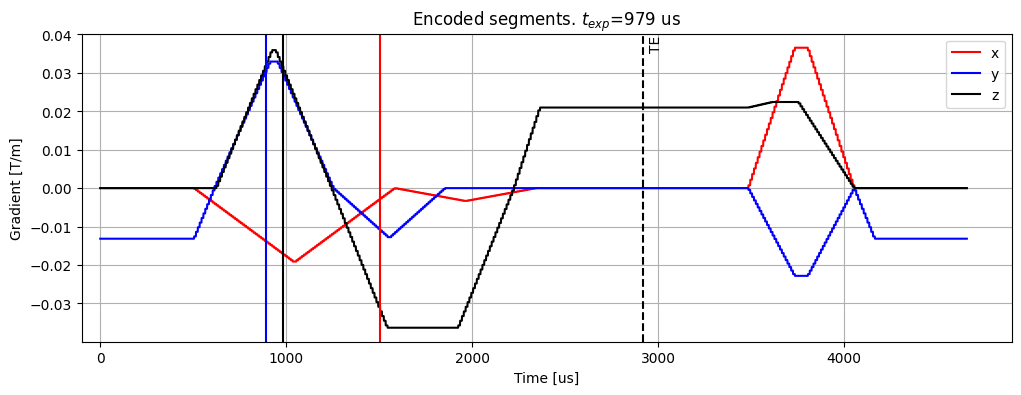

In [136]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(gx_enc.to_numpy(), color='r', label='x')
ax.plot(gy_enc.to_numpy(), color='b', label='y')
ax.plot(gz_enc.to_numpy(), color='k', label='z')
plt.axvline(te, color='k', linestyle='--')
plt.text(te*1.01, 0.95, 'TE', rotation=90, transform=ax.get_xaxis_text1_transform(0)[0])

plt.axvline(tgx, color='r')
plt.axvline(tgy, color='b')
plt.axvline(tgz, color='k')

ax.grid()
plt.ylabel('Gradient [T/m]')
plt.xlabel('Time [us]')
plt.title(f'Encoded segments. $t_{{exp}}$={int(t_ref*1e6)} us')
ax.legend()
ax.set_xlim(xlim)
plt.savefig(f'gradient_encoded_{int(t_ref*1e6)}us.svg')

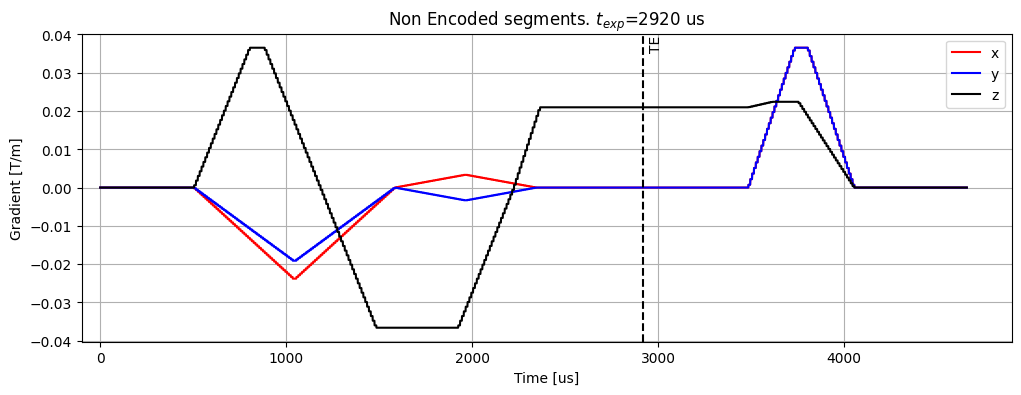

In [102]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(gx_nonenc.to_numpy(), color='r', label='x')
ax.plot(gy_nonenc.to_numpy(), color='b', label='y')
ax.plot(gz_nonenc.to_numpy(), color='k', label='z')
plt.axvline(te, color='k', linestyle='--')
plt.text(te*1.01, 0.95, 'TE', rotation=90, transform=ax.get_xaxis_text1_transform(0)[0])
ax.grid()
plt.ylabel('Gradient [T/m]')
plt.xlabel('Time [us]')
plt.title(f'Non Encoded segments. $t_{{exp}}$={int(t_ref*1e6)} us')
ax.legend()
ax.set_xlim(xlim)
plt.savefig(f'gradient_nonencoded_{int(t_ref*1e6)}us.svg')

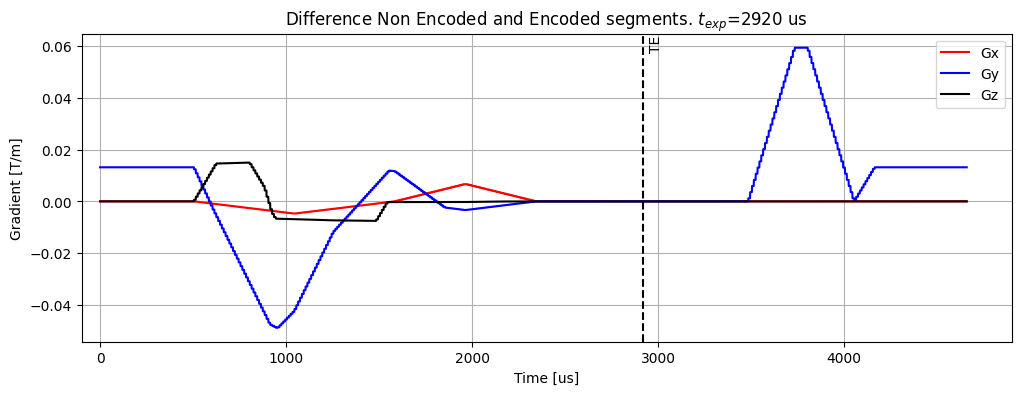

In [103]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(gx_nonenc.to_numpy()[0:len(gx_nonenc)] - gx_enc.to_numpy()[0:len(gx_nonenc)], color='r', label='Gx')
ax.plot(gy_nonenc.to_numpy()[0:len(gy_enc)] - gy_enc.to_numpy()[0:len(gy_enc)], color='b', label='Gy')
ax.plot(gz_nonenc.to_numpy()[0:len(gz_nonenc)] - gz_enc.to_numpy()[0:len(gz_nonenc)], color='k', label='Gz')
plt.axvline(te, color='k', linestyle='--')
plt.text(te*1.01, 0.95, 'TE', rotation=90, transform=ax.get_xaxis_text1_transform(0)[0])
ax.grid()
plt.ylabel('Gradient [T/m]')
plt.xlabel('Time [us]')
plt.title(f'Difference Non Encoded and Encoded segments. $t_{{exp}}$={int(t_ref*1e6)} us')
ax.legend()
ax.set_xlim(xlim)
plt.savefig(f'gradient_diff_{int(t_ref*1e6)}us.svg')

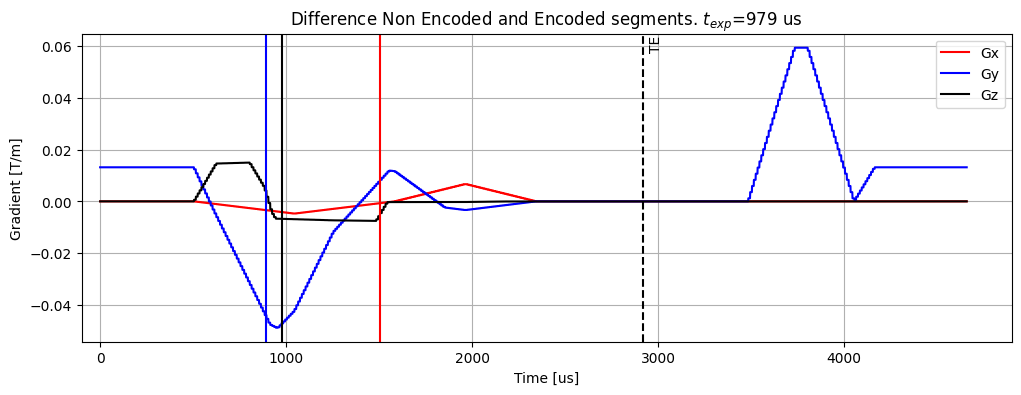

In [138]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(gx_nonenc.to_numpy()[0:len(gx_nonenc)] - gx_enc.to_numpy()[0:len(gx_nonenc)], color='r', label='Gx')
ax.plot(gy_nonenc.to_numpy()[0:len(gy_enc)] - gy_enc.to_numpy()[0:len(gy_enc)], color='b', label='Gy')
ax.plot(gz_nonenc.to_numpy()[0:len(gz_nonenc)] - gz_enc.to_numpy()[0:len(gz_nonenc)], color='k', label='Gz')
plt.axvline(te, color='k', linestyle='--')
plt.text(te*1.01, 0.95, 'TE', rotation=90, transform=ax.get_xaxis_text1_transform(0)[0])
ax.grid()
plt.ylabel('Gradient [T/m]')
plt.xlabel('Time [us]')
plt.title(f'Difference Non Encoded and Encoded segments. $t_{{exp}}$={int(t_ref*1e6)} us')
ax.legend()
ax.set_xlim(xlim)


plt.axvline(tgx, color='r')
plt.axvline(tgy, color='b')
plt.axvline(tgz, color='k')

plt.savefig(f'gradient_diff_tg_{int(t_ref*1e6)}us.svg')

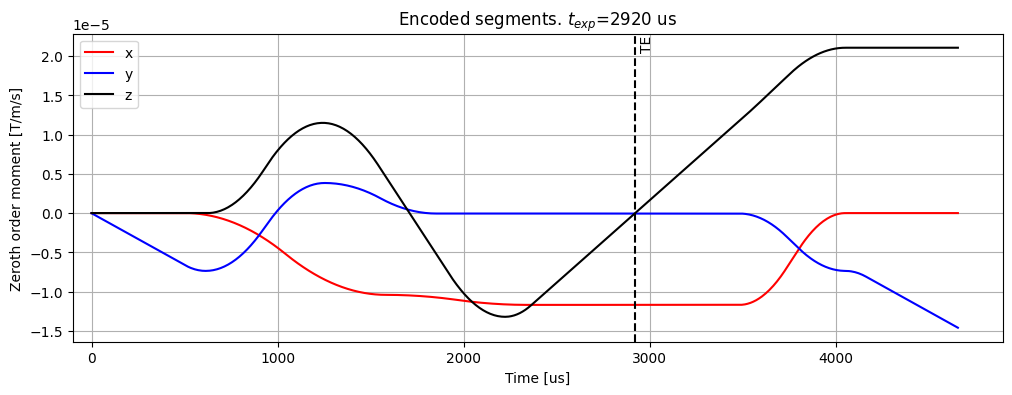

In [104]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(m0x_enc, color='r', label='x')
ax.plot(m0y_enc, color='b', label='y')
ax.plot(m0z_enc, color='k', label='z')
plt.axvline(te, color='k', linestyle='--')
plt.text(te*1.01, 0.95, 'TE', rotation=90, transform=ax.get_xaxis_text1_transform(0)[0])
ax.grid()
plt.ylabel('Zeroth order moment [T/m/s]')
plt.xlabel('Time [us]')
plt.title(f'Encoded segments. $t_{{exp}}$={int(t_ref*1e6)} us')
ax.legend()
ax.set_xlim(xlim)
plt.savefig(f'zeromoment_encoded_{int(t_ref*1e6)}us.svg')

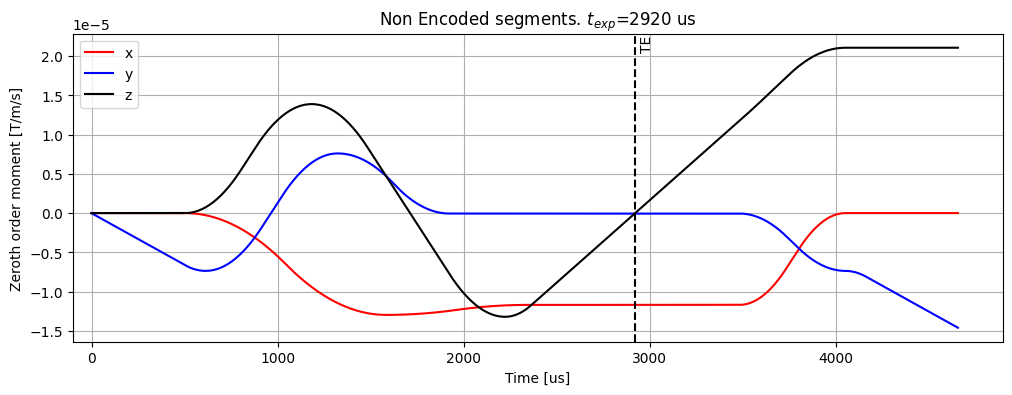

In [105]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(m0x_nonenc, color='r', label='x')
ax.plot(m0y_nonenc, color='b', label='y')
ax.plot(m0z_nonenc, color='k', label='z')
plt.axvline(te, color='k', linestyle='--')
plt.text(te*1.01, 0.95, 'TE', rotation=90, transform=ax.get_xaxis_text1_transform(0)[0])
ax.grid()
plt.ylabel('Zeroth order moment [T/m/s]')
plt.xlabel('Time [us]')
plt.title(f'Non Encoded segments. $t_{{exp}}$={int(t_ref*1e6)} us')
ax.legend()
ax.set_xlim(xlim)
plt.savefig(f'zeromoment_nonencoded_{int(t_ref*1e6)}us.svg')

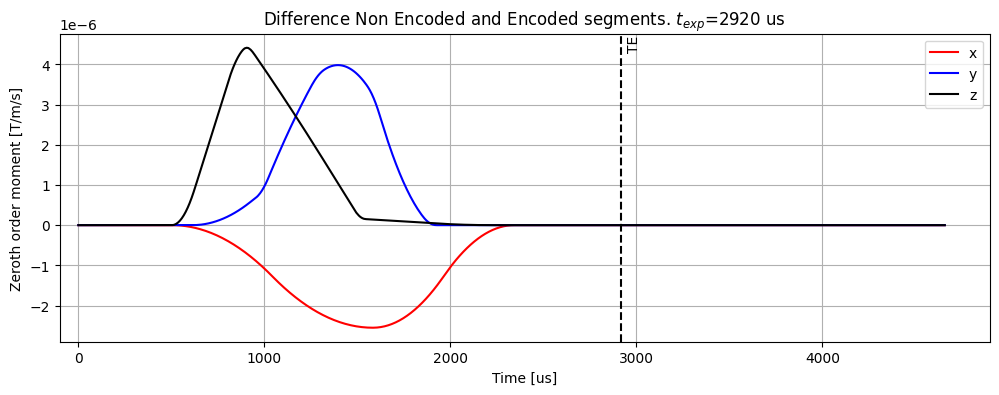

In [106]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(m0x_nonenc[0:len(m0x_nonenc)] - m0x_enc[0:len(m0x_nonenc)], color='r', label='x')
ax.plot(m0y_nonenc - m0y_enc, color='b', label='y')
ax.plot(m0z_nonenc - m0z_enc, color='k', label='z')
plt.axvline(te, color='k', linestyle='--')
plt.text(te*1.01, 0.95, 'TE', rotation=90, transform=ax.get_xaxis_text1_transform(0)[0])
ax.grid()
plt.ylabel('Zeroth order moment [T/m/s]')
plt.xlabel('Time [us]')
plt.title(f'Difference Non Encoded and Encoded segments. $t_{{exp}}$={int(t_ref*1e6)} us')
ax.legend()
ax.set_xlim(xlim)
plt.savefig(f'zeromoment_diff_{int(t_ref*1e6)}us.svg')

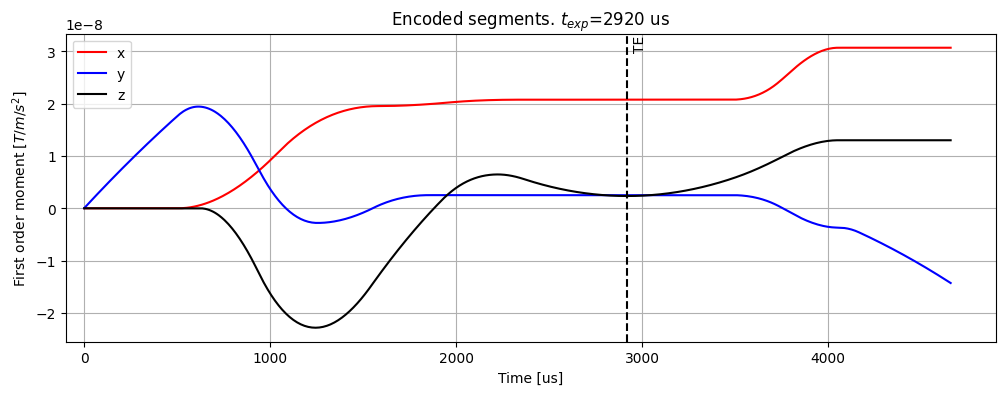

In [107]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(m1x_enc, color='r', label='x')
ax.plot(m1y_enc, color='b', label='y')
ax.plot(m1z_enc, color='k', label='z')
plt.axvline(te, color='k', linestyle='--')
plt.text(te*1.01, 0.95, 'TE', rotation=90, transform=ax.get_xaxis_text1_transform(0)[0])
ax.grid()
plt.ylabel('First order moment [$T/m/s^2$]')
plt.xlabel('Time [us]')
plt.title(f'Encoded segments. $t_{{exp}}$={int(t_ref*1e6)} us')
ax.legend()
ax.set_xlim(xlim)
plt.savefig(f'firstmoment_encoded_{int(t_ref*1e6)}us.svg')

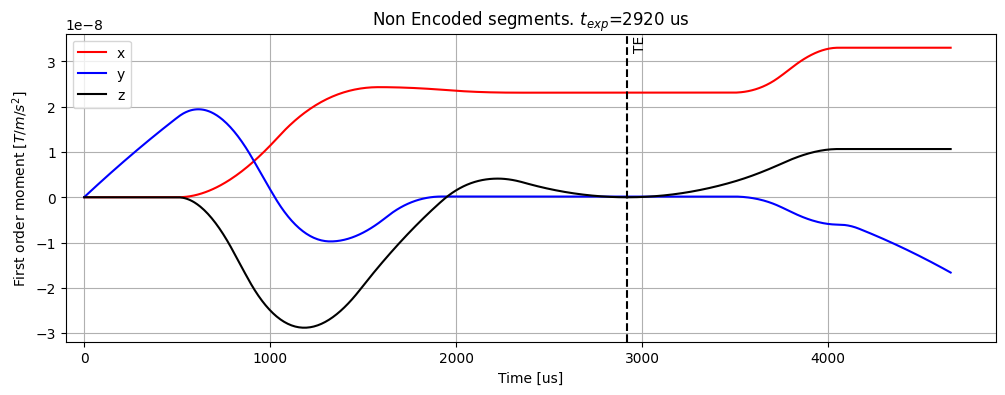

In [108]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(m1x_nonenc, color='r', label='x')
ax.plot(m1y_nonenc, color='b', label='y')
ax.plot(m1z_nonenc, color='k', label='z')
plt.axvline(te, color='k', linestyle='--')
plt.text(te*1.01, 0.95, 'TE', rotation=90, transform=ax.get_xaxis_text1_transform(0)[0])
ax.grid()
plt.ylabel('First order moment [$T/m/s^2$]')
plt.xlabel('Time [us]')
plt.title(f'Non Encoded segments. $t_{{exp}}$={int(t_ref*1e6)} us')
ax.legend()
ax.set_xlim(xlim)
plt.savefig(f'firstmoment_nonencoded_{int(t_ref*1e6)}us.svg')

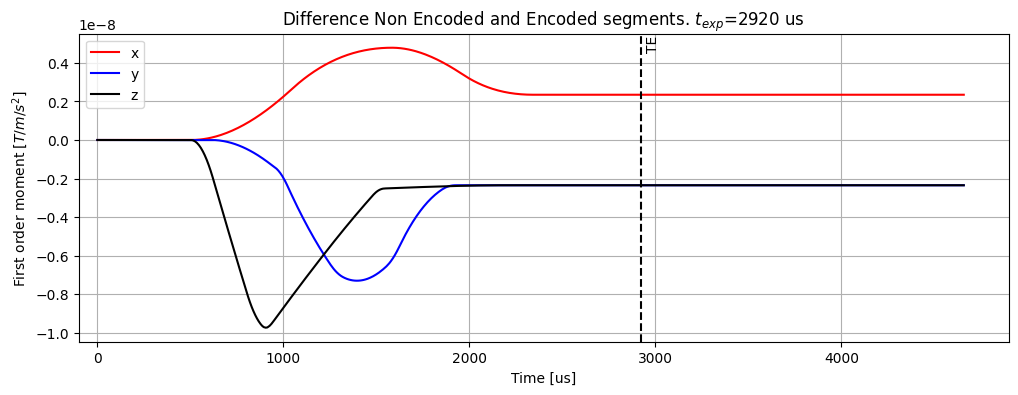

In [109]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(m1x_nonenc[0:len(m1x_nonenc)] - m1x_enc[0:len(m1x_nonenc)], color='r', label='x')
ax.plot(m1y_nonenc - m1y_enc, color='b', label='y')
ax.plot(m1z_nonenc - m1z_enc, color='k', label='z')
plt.axvline(te, color='k', linestyle='--')
plt.text(te*1.01, 0.95, 'TE', rotation=90, transform=ax.get_xaxis_text1_transform(0)[0])
ax.grid()
plt.ylabel('First order moment [$T/m/s^2$]')
plt.xlabel('Time [us]')
plt.title(f'Difference Non Encoded and Encoded segments. $t_{{exp}}$={int(t_ref*1e6)} us')
ax.legend()
ax.set_xlim(xlim)
plt.savefig(f'firstmoment_diff_{int(t_ref*1e6)}us.svg')

C:\Users\dillin01\AppData\Local\Temp\1\ipykernel_32464\2129923992.py:1: RuntimeWarning: divide by zero encountered in divide
  vencx = np.pi / (gamma*(m1x_nonenc[0:len(m1x_nonenc)] - m1x_enc[0:len(m1x_nonenc)]))
C:\Users\dillin01\AppData\Local\Temp\1\ipykernel_32464\2129923992.py:2: RuntimeWarning: divide by zero encountered in divide
  vency = np.pi / (gamma*(m1y_nonenc - m1y_enc))
C:\Users\dillin01\AppData\Local\Temp\1\ipykernel_32464\2129923992.py:3: RuntimeWarning: divide by zero encountered in divide
  vencz = np.pi / (gamma*(m1z_nonenc - m1z_enc))


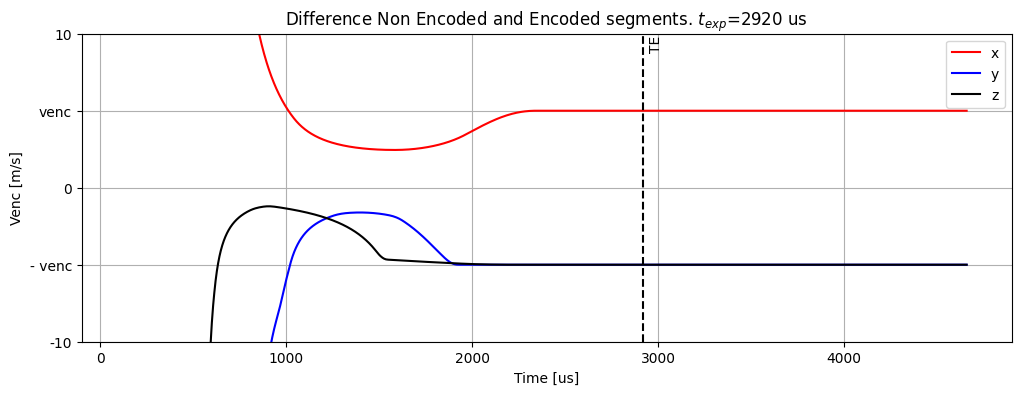

In [110]:
vencx = np.pi / (gamma*(m1x_nonenc[0:len(m1x_nonenc)] - m1x_enc[0:len(m1x_nonenc)]))
vency = np.pi / (gamma*(m1y_nonenc - m1y_enc))
vencz = np.pi / (gamma*(m1z_nonenc - m1z_enc))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(vencx, color='r', label='x')
ax.plot(vency, color='b', label='y')
ax.plot(vencz, color='k', label='z')
plt.axvline(te, color='k', linestyle='--')
plt.text(te*1.01, 0.95, 'TE', rotation=90, transform=ax.get_xaxis_text1_transform(0)[0])
ax.grid()
ax.set_ylim((-10, 10))
ax.set_yticks((-10, -5, 0, 5, 10))
ax.set_yticklabels(('-10', '- venc', '0', 'venc', '10'))
plt.ylabel('Venc [m/s]')
plt.xlabel('Time [us]')
plt.title(f'Difference Non Encoded and Encoded segments. $t_{{exp}}$={int(t_ref*1e6)} us')
ax.legend()
ax.set_xlim(xlim)
plt.savefig(f'firstmoment_diff_venc_{int(t_ref*1e6)}us.svg')

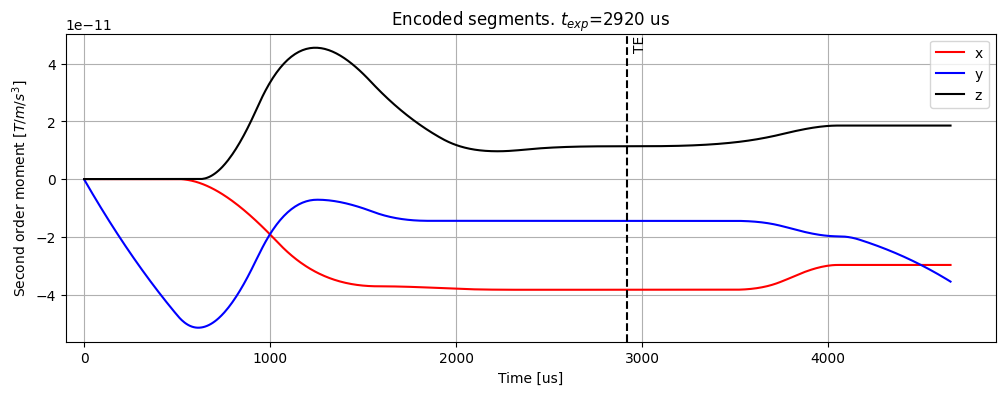

In [111]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(m2x_enc, color='r', label='x')
ax.plot(m2y_enc, color='b', label='y')
ax.plot(m2z_enc, color='k', label='z')
plt.axvline(te, color='k', linestyle='--')
plt.text(te*1.01, 0.95, 'TE', rotation=90, transform=ax.get_xaxis_text1_transform(0)[0])
ax.grid()
plt.ylabel('Second order moment [$T/m/s^3$]')
plt.xlabel('Time [us]')
plt.title(f'Encoded segments. $t_{{exp}}$={int(t_ref*1e6)} us')
ax.legend()
ax.set_xlim(xlim)
plt.savefig(f'secondmoment_encoded_{int(t_ref*1e6)}us.svg')

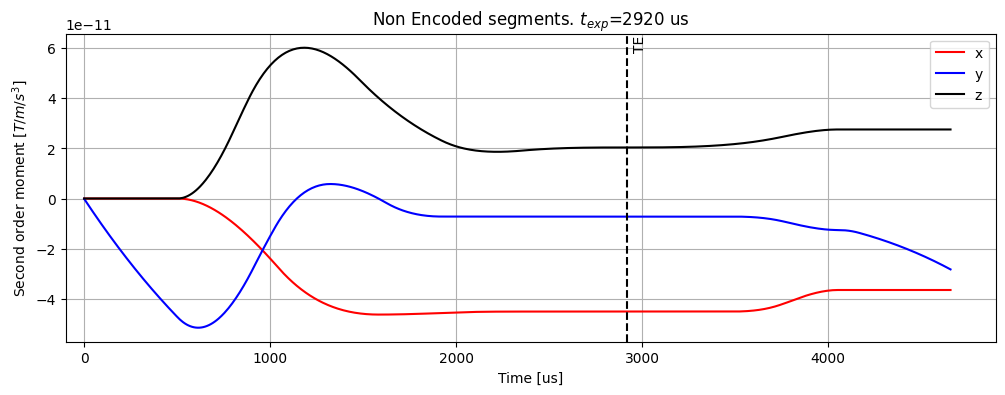

In [112]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(m2x_nonenc, color='r', label='x')
ax.plot(m2y_nonenc, color='b', label='y')
ax.plot(m2z_nonenc, color='k', label='z')
plt.axvline(te, color='k', linestyle='--')
plt.text(te*1.01, 0.95, 'TE', rotation=90, transform=ax.get_xaxis_text1_transform(0)[0])
ax.grid()
plt.ylabel('Second order moment [$T/m/s^3$]')
plt.xlabel('Time [us]')
plt.title(f'Non Encoded segments. $t_{{exp}}$={int(t_ref*1e6)} us')
ax.legend()
ax.set_xlim(xlim)
plt.savefig(f'secondmoment_nonencoded_{int(t_ref*1e6)}us.svg')

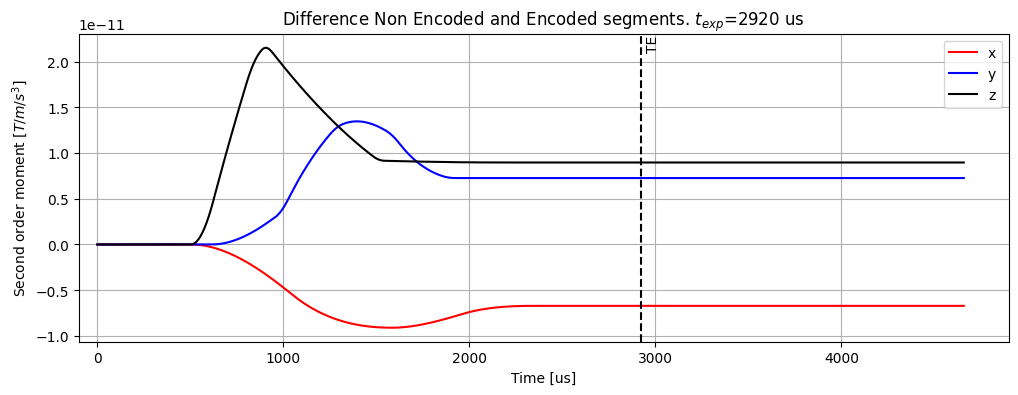

In [113]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(m2x_nonenc[0:len(m2x_nonenc)] - m2x_enc[0:len(m2x_nonenc)], color='r', label='x')
ax.plot(m2y_nonenc - m2y_enc, color='b', label='y')
ax.plot(m2z_nonenc - m2z_enc, color='k', label='z')
plt.axvline(te, color='k', linestyle='--')
plt.text(te*1.01, 0.95, 'TE', rotation=90, transform=ax.get_xaxis_text1_transform(0)[0])
ax.grid()
plt.ylabel('Second order moment [$T/m/s^3$]')
plt.xlabel('Time [us]')
plt.title(f'Difference Non Encoded and Encoded segments. $t_{{exp}}$={int(t_ref*1e6)} us')
ax.legend()
ax.set_xlim(xlim)
plt.savefig(f'secondmoment_diff_{int(t_ref*1e6)}us.svg')

C:\Users\dillin01\AppData\Local\Temp\1\ipykernel_32464\730350177.py:1: RuntimeWarning: divide by zero encountered in divide
  aencx = np.pi / (1/2*gamma*(m2x_nonenc[0:len(m2x_nonenc)] - m2x_enc[0:len(m2x_nonenc)]))
C:\Users\dillin01\AppData\Local\Temp\1\ipykernel_32464\730350177.py:2: RuntimeWarning: divide by zero encountered in divide
  aency = np.pi / (1/2*gamma*(m2y_nonenc - m2y_enc))
C:\Users\dillin01\AppData\Local\Temp\1\ipykernel_32464\730350177.py:3: RuntimeWarning: divide by zero encountered in divide
  aencz = np.pi / (1/2*gamma*(m2z_nonenc - m2z_enc))


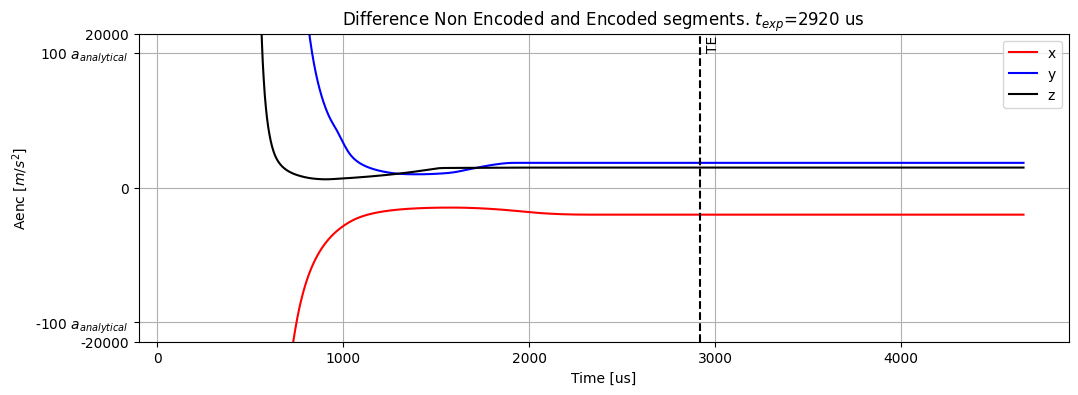

In [114]:
aencx = np.pi / (1/2*gamma*(m2x_nonenc[0:len(m2x_nonenc)] - m2x_enc[0:len(m2x_nonenc)]))
aency = np.pi / (1/2*gamma*(m2y_nonenc - m2y_enc))
aencz = np.pi / (1/2*gamma*(m2z_nonenc - m2z_enc))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(aencx, color='r', label='x')
ax.plot(aency, color='b', label='y')
ax.plot(aencz, color='k', label='z')
plt.axvline(te, color='k', linestyle='--')
plt.text(te*1.01, 0.95, 'TE', rotation=90, transform=ax.get_xaxis_text1_transform(0)[0])
ax.grid()
ax.set_ylim((-20000, 20000))
ax.set_yticks((-20000, -17500, 0, 17500, 20000))
ax.set_yticklabels(('-20000', '-100 $a_{analytical}$', '0', '100 $a_{analytical}$', '20000'))
plt.ylabel('Aenc [$m/s^2$]')
plt.xlabel('Time [us]')
plt.title(f'Difference Non Encoded and Encoded segments. $t_{{exp}}$={int(t_ref*1e6)} us')
ax.legend()
ax.set_xlim(xlim)
plt.savefig(f'secondmoment_diff_aenc_{int(t_ref*1e6)}us.svg')

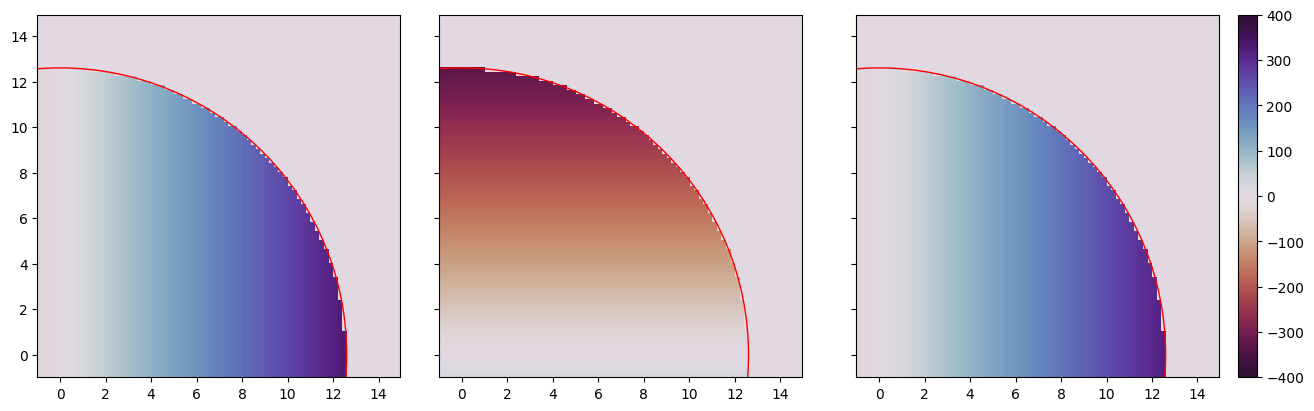

328.71672010655533


In [115]:
from matplotlib.colors import LinearSegmentedColormap

# Shape of matrices
shape = 224
imgsize = 22.4
# Phantom radius
r = np.linspace(-imgsize, imgsize, shape)
# r_phan = 6.47*2 #cm
r_phan = 6.3*2 #cm

# vmax at border of image
rpm = 500
vmax = rpm / 60 * np.pi * imgsize
venc = 400

center_pre = (0, 0) # Circle center

cmap = matplotlib.colormaps.get_cmap('twilight')  # viridis is the default colormap for imshow

# Number of colors to sample
N = 256
# Convert to a list of colors
colors = cmap(np.linspace(0, 1, N))

# Shift the colormap by 0.5 (center goes to the ends)
shifted_colors = np.roll(colors, N // 2, axis=0)

# Create a new colormap
shifted_cmap = LinearSegmentedColormap.from_list('shifted_twilight', shifted_colors, N=N)

cmap = shifted_cmap
# cmap.set_bad(color='white')
cmap.set_bad(color=cmap(0.5))

xan,yan = np.meshgrid(np.linspace(-imgsize,imgsize,shape),np.linspace(-imgsize,imgsize,shape))

vxan = xan / imgsize * vmax
vyan = yan / imgsize * vmax


dist_from_center2 = np.sqrt(xan**2 + yan**2)
mask2 = dist_from_center2 <= r_phan
mask2 = np.ones_like(xan)
mask2[~(dist_from_center2 <= r_phan).astype(bool)] = np.nan

vxanccw = xan + 0 # eddy current shift

fig0, ax0 = plt.subplots(1, 3, figsize=(13, 4), layout="constrained", sharex=True, sharey=True)

ax0[0].imshow(vxan*mask2, extent=(-imgsize,imgsize,-imgsize,imgsize), vmin=-venc, vmax=venc, cmap=cmap)
circle = plt.Circle(center_pre, r_phan, color='r', alpha=1, fill=False)
ax0[0].add_patch(circle)

ax0[1].imshow(vyan*mask2, extent=(-imgsize,imgsize,-imgsize,imgsize), vmin=-venc, vmax=venc, cmap=cmap)
circle2 = plt.Circle(center_pre, r_phan, color='r', alpha=1, fill=False)
ax0[1].add_patch(circle2)

im2 = ax0[2].imshow(vxan*mask2 - vxanccw*mask2, extent=(-imgsize,imgsize,-imgsize,imgsize), vmin=-venc, vmax=venc, cmap=cmap)
circle3 = plt.Circle(center_pre, r_phan, color='r', alpha=1, fill=False)
ax0[2].add_patch(circle3)

fig0.colorbar(im2)
ax0[0].set_xlim(-1,imgsize/1.5)
ax0[0].set_ylim(-1,imgsize/1.5)

plt.savefig('analytical_vel_zoom.svg')

plt.show()

print(np.nanmax(vxan*mask2))

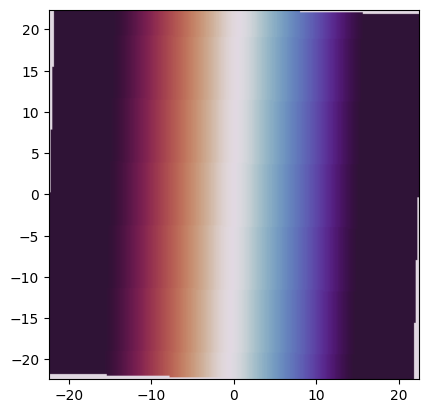

In [116]:
from scipy import ndimage

# homogeneous coordinate matrix, no rotation, no shift
rot = np.eye(2, 2)
rot_angle = 1.5 * (2*np.pi) / 360
rot[0, 0] = np.cos(rot_angle)
rot[0, 1] = -np.sin(rot_angle)
rot[1, 0] = np.sin(rot_angle)
rot[1, 1] = np.cos(rot_angle)

# center = np.array(xan.shape)[::-1] // 2 + (0, 10)  # (width, height)# Compute the offset so the rotation is around the center
center = np.array(xan.shape)[::-1] // 2   # (width, height)# Compute the offset so the rotation is around the center
offset = center - rot @ center

rot_vxan = np.roll(vxan, shift=center)

rot_vxan = ndimage.affine_transform(input=rot_vxan, matrix=rot, order=0, mode='constant', cval=np.nan, offset=offset)

plt.imshow(rot_vxan, extent=(-imgsize,imgsize,-imgsize,imgsize), vmin=-venc, vmax=venc, cmap=cmap)
plt.show()

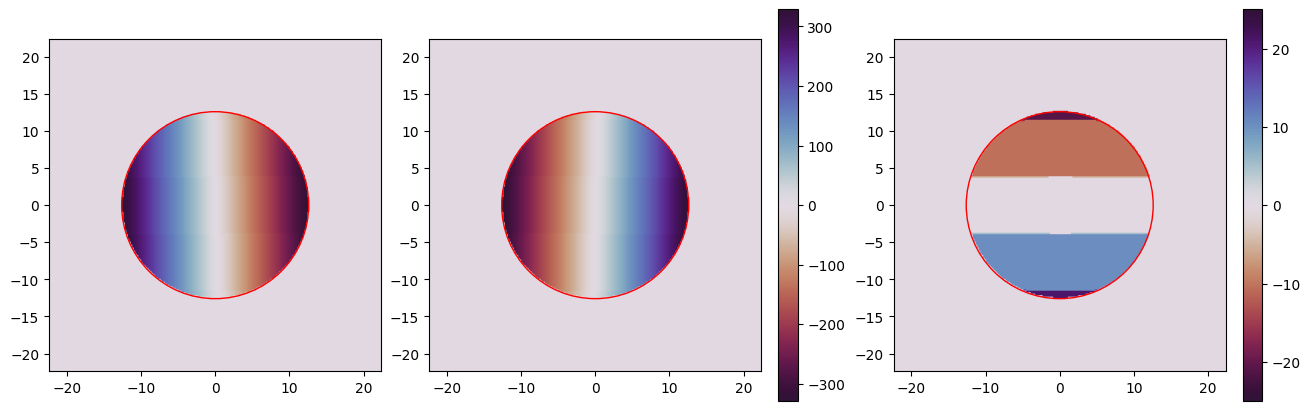

In [117]:
fig0, ax0 = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")

im_rot1 = ax0[0].imshow(np.flip(rot_vxan*mask2, axis=1), extent=(-imgsize,imgsize,-imgsize,imgsize), cmap=cmap)
circle = plt.Circle(center_pre, r_phan, color='r', alpha=1, fill=False)
ax0[0].add_patch(circle)
im_rot2 = ax0[1].imshow(rot_vxan*mask2, extent=(-imgsize,imgsize,-imgsize,imgsize), cmap=cmap)
plt.colorbar(mappable=im_rot2, ax=ax0[1])
circle2 = plt.Circle(center_pre, r_phan, color='r', alpha=1, fill=False)
ax0[1].add_patch(circle2)
im_sum = ax0[2].imshow(np.flip(rot_vxan*mask2, axis=1) + rot_vxan*mask2, extent=(-imgsize,imgsize,-imgsize,imgsize), cmap=cmap, vmin=-25, vmax=25)
plt.colorbar(mappable=im_sum, ax=ax0[2])
circle3 = plt.Circle(center_pre, r_phan, color='r', alpha=1, fill=False)
ax0[2].add_patch(circle3)